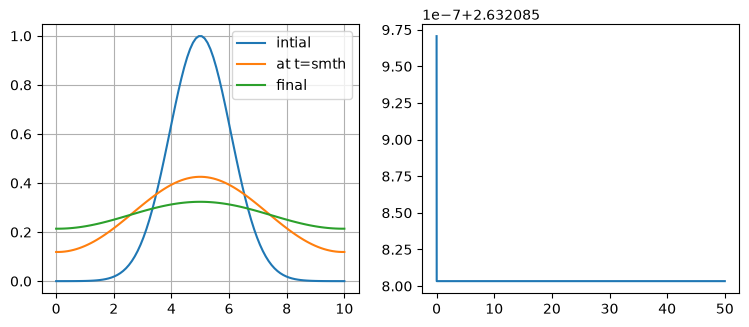

In [5]:
import numpy as np
import matplotlib.pyplot as plt

N = 100
dx = 0.1
L = dx * N
dt = 0.01
t_end = 50.0

D = 0.1
C = D * dt / dx**2
assert C < 0.5, "Stability violated"

x = np.linspace(0, L, N)
t = np.arange(0, t_end+dt, dt)

rho0 = np.exp(-((x - L/2)/1.5)**2)
rho = rho0.copy()
rho_temp = np.zeros(N)
rho_history = [rho.copy()]
total_particles = [np.sum(rho[1:-1]) * dx]

for n in range(len(t)):
    for i in range(1, N-1):
        rho_temp[i] = rho[i] + C * (rho[i+1] + rho[i-1] - 2*rho[i])
    
    rho_temp[0] = rho_temp[1]
    rho_temp[-1] = rho_temp[-2]
    rho = rho_temp.copy()
    rho_history.append(rho.copy())
    total_particles.append(np.sum(rho[1:-1]) * dx)

plt.figure(figsize=(9, 3.5))
plt.subplot(1, 2, 1)

plt.plot(x, rho_history[0], label="intial")
plt.plot(x, rho_history[len(t)//2], label=f"at t=smth")
plt.plot(x, rho_history[-1], label='final')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(t, total_particles[:-1])


In [7]:
L = 2 * np.pi 
N = 100
dx = L / N
dt = 0.001
nt = 200
D = 0.1
C = D * dt / dx**2
assert C < 0.5, 'Stability vilolated'

x = np.linspace(0, L, N, endpoint=False)
k1, k2 = 1, 4
rho1 = np.sin(k1 * x)
rho2 = np.sin(k2 * x)

target_t = 0.5
nt = int(target_t//dt)

for n in range(nt):
    rho1_new = rho1 + C * (np.roll(rho1, -1) + np.roll(rho1, 1) - 2 * rho1)
    rho2_new = rho2 + C * (np.roll(rho2, -1) + np.roll(rho2, 1) - 2 * rho2)
    rho1, rho2 = rho1_new, rho2_new

print(np.max(rho1), np.exp(-D * k1**2 * target_t))
print(np.max(rho2), np.exp(-D * k2**2 * target_t))

0.951337795449375 0.951229424500714
0.45076274167087055 0.44932896411722156


2.2222222222222223


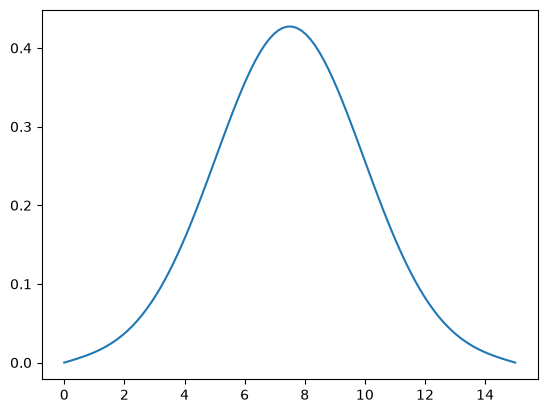

In [8]:
N = 100
dx = 0.15
L = dx * N
D = 0.05
dt = 1.0
C = D* (dt / dx**2)
print(C)


x = np.linspace(0, L, N)
rho = np.exp(-((x - L/2)/1.5)**2)

main_diag = (1 + 2 * C) * np.ones(N)
off_diag = -C * np.ones(N-1)
A = np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1)

A[0, :] = 0 ; A[0, 0] = 1.0
A[-1, :] = 0 ; A[-1, -1] = 1.0

for step in range(50):
    rhs = rho.copy()
    rhs[0] = 0.0
    rhs[-1] = 0.0
    rho = np.linalg.solve(A, rhs)

plt.plot(x, rho)

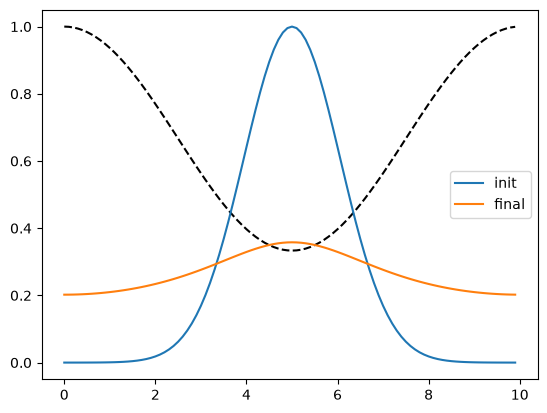

In [12]:
N = 100
dx = 0.1
L = N*dx
dt = 0.01
x = np.linspace(0, L, N, endpoint=False)
D = 0.1 * (1.0 + 0.5 * np.cos(2 * np.pi * x / L))
D_half = 0.5 * (D + np.roll(D, -1))

rho = np.exp(-((x - L/2)/1.5)**2)
rho0 = rho.copy()
for i in range(5000):
    flux = -D_half * (np.roll(rho, -1) - rho)/dx
    rho = rho - (dt/dx) * (flux - np.roll(flux, 1))

plt.plot(x, D/np.max(D), 'k--')
plt.plot(x, rho0, label='init')
plt.plot(x, rho, label='final')
plt.legend()
plt.show()

In [ ]:
N = 100
dx = 0.1
L = N*dx
dt = 0.01
x = np.linspace(0, L, N, endpoint=False)
y = 